# Session 5 lecture: Metrics and KPIs

<p class="lead">
A metric is only as good as its definition. This lecture shows what makes a metric useful, how to write it down so everyone calculates the same number, and the traps that make honest totals and averages tell the wrong story.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/05_metrics_and_kpis_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer the quiz at the end of the [Session 4 lecture](04_descriptive_statistics_lecture.md). Write short answers; we discuss them together.

---

## What you will be able to explain

1. What makes a metric **actionable**, **defined** and **comparable**, and how a KPI differs from any other metric.
2. What goes into a **metric contract**: grain, numerator, denominator, scope, zero and missing rules, owner.
3. Why a **ratio of sums** is not the **mean of ratios**, and how the overall rate is a **weighted** average of group rates.
4. Why **distinct counts** do not add up across groups or periods.
5. How **Simpson's paradox** can reverse a comparison when groups are combined.
6. Why a metric that becomes a target can stop measuring what you wanted (**Goodhart's law**).

This lecture builds on [How statistics can mislead](../foundations/misleading-statistics.md), especially Simpson's paradox and the averages traps. In the **Lab** you build a segment KPI table that reconciles, write your own metric contract and analyse the Berkeley admissions data.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the setup cell first.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
df = load_orders()
print("Order lines:", len(df))
print("Orders:     ", df["order_id"].nunique())

Order lines: 6815
Orders:      3388


---

## Part 1: What makes a good metric?

A **metric** is a number calculated the same way every time, so you can compare it over time or across groups. A **KPI** (key performance indicator) is a metric that a team has agreed to watch because it is tied to a goal.

A good metric is:

| Quality | Question to ask | Weak example | Better example |
|---|---|---|---|
| **Actionable** | If it moves, does someone know what to do? | Total page views | Share of visitors who reach checkout |
| **Defined** | Would two analysts get the same number? | "Average order" | Sales ÷ distinct orders, orders placed in the period |
| **Comparable** | Can we compare groups or periods fairly? | Total sales by region (regions differ in size) | Sales per order, profit ratio |
| **Timely** | Is it available when the decision is made? | Annual survey for a weekly decision | Weekly order count |
| **Hard to game** | Can it improve while the business gets worse? | Number of calls closed | Calls closed **and** repeat calls within 7 days |

> **Vanity metrics**
>
> A *vanity metric* goes up and looks good, but does not help a decision: total registered users, all-time downloads, total impressions. They almost always grow. Ask: *"What would we do differently if this number fell?"* If there is no answer, it is not a KPI.

> **Check your understanding 1**
>
> A manager wants to track "total sales" to compare four regional teams. Which quality is weakest, and what metric would you suggest alongside it?

---

## Part 2: Metric contracts

A **metric contract** is a short written definition that removes every choice an analyst could make differently. Without one, two people can both be "right" and still report different numbers.

| Field | Question it answers | Example: average order value (AOV) |
|---|---|---|
| **Name** | What do we call it? | Average order value |
| **Purpose** | Which decision does it inform? | Compare how much customers spend per order across segments |
| **Grain** | What is one row in the data? | One order line |
| **Numerator** | What is added up on top? | Sum of `sales` |
| **Denominator** | What is counted below? | Number of distinct `order_id` |
| **Scope and filters** | Which rows and dates count? | Orders placed 2023-01-01 to 2025-12-31; no other filters |
| **Zero and missing rules** | What if the denominator is 0 or values are missing? | No orders → "not available" (`NaN`), never 0 |
| **Unit and display** | How is it shown? | Source monetary units, 2 decimals, no currency symbol |
| **Owner** | Who decides if the definition changes? | Retail analytics lead |

### Predict, then reveal: one name, two numbers

Two analysts are both asked for "average order value". One divides Sales by the number of **rows**; the other divides by the number of **distinct orders**.

> **Predict, then reveal**
>
> Which answer is larger, and roughly by how much? Think about how many lines a typical order has.

In [3]:
sales = df["sales"].sum()
per_row = sales / len(df)
per_order = sales / df["order_id"].nunique()

print("Analyst 1, Sales per row (order line):", round(per_row, 2))
print("Analyst 2, Sales per distinct order:  ", round(per_order, 2))
print("Ratio of the two:                     ", round(per_order / per_row, 2))

Analyst 1, Sales per row (order line): 231.98
Analyst 2, Sales per distinct order:   466.64
Ratio of the two:                      2.01


Both analysts calculated *something* correctly. Only one calculated what the name promises. The ratio of the two is exactly the average number of lines per order. A contract that states the **denominator** prevents this argument.

A contract can also live in code, next to the calculation, so the definition travels with the number:

In [4]:
aov_contract = {
    "name": "Average order value (AOV)",
    "purpose": "Compare spend per order across customer segments",
    "grain": "One order line",
    "numerator": "Sum of sales",
    "denominator": "Number of distinct order_id",
    "scope": "Orders placed 2023-01-01 to 2025-12-31",
    "zero_rule": "No orders in scope -> not available (NaN), never 0",
    "unit": "Source monetary units, 2 decimals, no currency symbol",
    "owner": "Retail analytics lead",
}
pd.Series(aov_contract, name="definition").to_frame()

,definition
name,Average order value (AOV)
purpose,Compare spend per order across customer segments
grain,One order line
numerator,Sum of sales
denominator,Number of distinct order_id
scope,Orders placed 2023-01-01 to 2025-12-31
zero_rule,"No orders in scope -> not available (NaN), nev..."
unit,"Source monetary units, 2 decimals, no currency..."
owner,Retail analytics lead


> **Check your understanding 2**
>
> A report shows "Return rate: 4%". Write three questions you would need answered (three contract fields) before you could reproduce that number.

---

## Part 3: Ratio of sums versus mean of ratios

Many KPIs are **ratios**: profit ÷ sales, conversions ÷ visits, late deliveries ÷ deliveries. When you combine groups, there are two tempting ways to get an overall ratio:

- **Ratio of sums:** add up all numerators, add up all denominators, then divide.
- **Mean of ratios:** calculate each group's ratio, then average them.

### Predict, then reveal: a big store and a tiny store

Two stores report their profit ratio. Store A is large; Store B is a small kiosk.

| Store | Sales | Profit |
|---|---|---|
| A | 10,000 | 1,000 |
| B | 100 | 50 |

> **Predict, then reveal**
>
> What is the company's overall profit ratio? Is it closer to Store A's ratio or to the simple average of the two ratios?

In [5]:
stores = pd.DataFrame({"sales": [10_000, 100], "profit": [1_000, 50]}, index=["A", "B"])
stores["profit_ratio"] = stores["profit"] / stores["sales"]

mean_of_ratios = stores["profit_ratio"].mean()
ratio_of_sums = stores["profit"].sum() / stores["sales"].sum()

print(stores)
print()
print("Mean of the two ratios:", f"{mean_of_ratios:.1%}")
print("Ratio of the sums:     ", f"{ratio_of_sums:.1%}")

   sales  profit  profit_ratio
A  10000    1000          0.10
B    100      50          0.50

Mean of the two ratios: 30.0%
Ratio of the sums:      10.4%


The kiosk's high ratio counts as much as the big store's in the simple mean, even though it sold a hundred times less. The **ratio of sums** is what the company actually earned per unit of sales.

### The overall ratio is a weighted average

The ratio of sums is not a mysterious new number. It is the average of the group ratios, **weighted by each group's share of the denominator**. Here the weights are each store's share of Sales:

In [6]:
weights = stores["sales"] / stores["sales"].sum()
weighted = (weights * stores["profit_ratio"]).sum()

print("Sales share (weights):")
print(weights.round(4))
print()
print("Weighted average of ratios:", f"{weighted:.1%}")
print("Ratio of sums:             ", f"{ratio_of_sums:.1%}")

Sales share (weights):
A   0.99
B   0.01
Name: sales, dtype: float64

Weighted average of ratios: 10.4%
Ratio of sums:              10.4%


The two printed numbers are identical. This gives you a rule you can use everywhere:

> **Totals first, then divide**
>
> To get a ratio for any combination of groups, add up the numerator and the denominator over those groups, then divide. A simple mean of group ratios is only correct when every group has the **same** denominator.

> **Check your understanding 3**
>
> A website reports a conversion rate for each of 30 days. Your manager wants "the conversion rate for the month". What should you calculate, and when would the simple average of the 30 daily rates give the same answer?

---

## Part 4: Weighted rates in practice

The same idea applies whenever a rate is compared across groups of different sizes. Here, three warehouses report their on-time delivery rate.

In [7]:
warehouses = pd.DataFrame({
    "deliveries": [5_000, 800, 200],
    "on_time":    [4_500, 760, 196],
}, index=["Central", "North", "Island"])
warehouses["on_time_rate"] = warehouses["on_time"] / warehouses["deliveries"]

print(warehouses)
print()
print("Simple mean of rates:      ", f"{warehouses['on_time_rate'].mean():.1%}")
print("Company on-time rate (sums):", f"{warehouses['on_time'].sum() / warehouses['deliveries'].sum():.1%}")

         deliveries  on_time  on_time_rate
Central        5000     4500          0.90
North           800      760          0.95
Island          200      196          0.98

Simple mean of rates:       94.3%
Company on-time rate (sums): 90.9%


The small warehouses have the best rates, so the simple mean makes the company look better than its customers experience. Customers experience **deliveries**, so deliveries are the right weight.

> **Which weight?**
>
> The weight is always the **denominator** of the rate: Sales for a profit ratio, orders for an order-level rate, visits for a conversion rate, employees for a turnover rate. If you are unsure, write the rate as a fraction and look at the bottom.

There is one case where an unweighted mean of rates is right: when the question is about the **groups themselves**, for example *"How does a typical warehouse perform?"* Then each warehouse counts once. Say so explicitly in the metric contract.

---

## Part 5: Distinct counts do not add up

Sums add up across groups: the Sales of three segments add up to total Sales. **Distinct counts** often do not, because the same item can appear in several groups.

### Predict, then reveal: customers per year

We count distinct customers in each year and add them up. Then we count distinct customers over all three years.

> **Predict, then reveal**
>
> Will the sum of the yearly counts be larger, smaller or equal to the three-year count? Why?

Customer counts use only the lines marked `customer_analysis_eligible == 1`, which excludes the few orders that carry two different customer IDs (Session 2). We disclose that exclusion every time we count customers.

In [8]:
eligible = df[df["customer_analysis_eligible"] == 1]
print("Lines excluded from customer counts:", len(df) - len(eligible))

by_year = eligible.groupby(eligible["order_date"].dt.year)["customer_id"].nunique()
print(by_year)
print()
print("Sum of yearly distinct customers:", by_year.sum())
print("Distinct customers, 2023-2025:   ", eligible["customer_id"].nunique())

Lines excluded from customer counts: 4
order_date
2023    605
2024    577
2025    649
Name: customer_id, dtype: int64

Sum of yearly distinct customers: 1831
Distinct customers, 2023-2025:    789


Most customers bought in more than one year, so they are counted once per year in the yearly totals but only once in the three-year count.

> **Non-additive measures**
>
> Distinct counts (customers, orders across categories, products), medians and percentiles, and ratios are **non-additive**: you cannot add the group values to get the total. Always recalculate them from the underlying rows for the total. Sums and plain counts of rows are **additive**.

> **Check your understanding 4**
>
> A dashboard shows distinct orders for each product category and a "Total" row that is the sum of the category values. Why is the total wrong, and would it be too high or too low?

---

## Part 6: Simpson's paradox

**Simpson's paradox** happens when a comparison holds in every group, but reverses (or disappears) when the groups are combined. It is the weighted-average idea from Part 3 with a twist: the two things being compared have **different mixes** across the groups.

### UC Berkeley graduate admissions, 1973

The [Foundations page](../foundations/misleading-statistics.md) told the story: across all departments, a higher share of men than women were admitted. Here are the published counts for the **six largest departments** (Bickel, Hammel and O'Connell, 1975).

In [9]:
berkeley = pd.DataFrame({
    "department": ["A", "B", "C", "D", "E", "F"],
    "men_applied":     [825, 560, 325, 417, 191, 373],
    "men_admitted":    [512, 353, 120, 138,  53,  22],
    "women_applied":   [108,  25, 593, 375, 393, 341],
    "women_admitted":  [ 89,  17, 202, 131,  94,  24],
}).set_index("department")

berkeley["men_rate"] = berkeley["men_admitted"] / berkeley["men_applied"]
berkeley["women_rate"] = berkeley["women_admitted"] / berkeley["women_applied"]
berkeley[["men_applied", "men_rate", "women_applied", "women_rate"]].round(3)

,men_applied,men_rate,women_applied,women_rate
department,,,,
A,825,0.62,108,0.82
B,560,0.63,25,0.68
C,325,0.37,593,0.34
D,417,0.33,375,0.35
E,191,0.28,393,0.24
F,373,0.06,341,0.07


> **Predict, then reveal**
>
> In how many of the six departments is the women's admission rate higher? Now predict: when we add the six departments together, which group will have the higher overall rate?

In [10]:
men_overall = berkeley["men_admitted"].sum() / berkeley["men_applied"].sum()
women_overall = berkeley["women_admitted"].sum() / berkeley["women_applied"].sum()

print("Departments where women's rate is higher:", (berkeley["women_rate"] > berkeley["men_rate"]).sum(), "of 6")
print("Six departments combined, men:  ", f"{men_overall:.1%}")
print("Six departments combined, women:", f"{women_overall:.1%}")

Departments where women's rate is higher: 4 of 6
Six departments combined, men:   44.5%
Six departments combined, women: 30.4%


### Why it reverses: different application mixes

The overall rate for each group is a weighted average of the department rates, weighted by **where that group applied**. Look at the share of each group's applications that went to each department, next to how hard each department was to get into.

In [11]:
mix = pd.DataFrame({
    "share_of_men_applying": berkeley["men_applied"] / berkeley["men_applied"].sum(),
    "share_of_women_applying": berkeley["women_applied"] / berkeley["women_applied"].sum(),
    "dept_admit_rate_all": (berkeley["men_admitted"] + berkeley["women_admitted"])
                           / (berkeley["men_applied"] + berkeley["women_applied"]),
})
mix.round(3)

,share_of_men_applying,share_of_women_applying,dept_admit_rate_all
department,,,
A,0.31,0.06,0.64
B,0.21,0.01,0.63
C,0.12,0.32,0.35
D,0.15,0.20,0.34
E,0.07,0.21,0.25
F,0.14,0.19,0.06


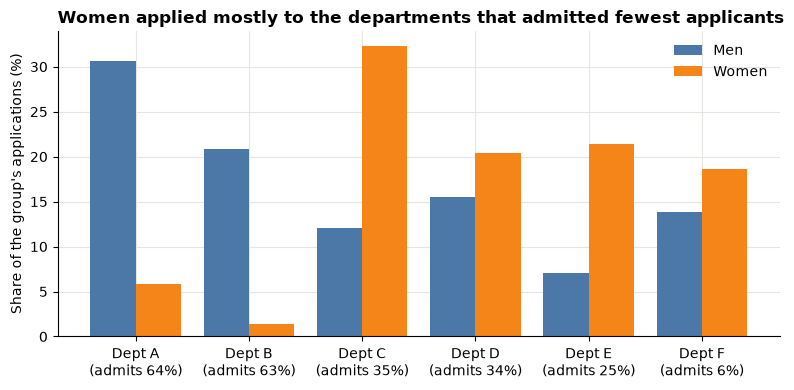

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(berkeley))
ax.bar([i - 0.2 for i in x], mix["share_of_men_applying"] * 100, width=0.4, label="Men", color="#4C78A8")
ax.bar([i + 0.2 for i in x], mix["share_of_women_applying"] * 100, width=0.4, label="Women", color="#F58518")
ax.set_xticks(list(x), [f"Dept {d}\n(admits {r:.0%})" for d, r in mix["dept_admit_rate_all"].items()])
ax.set_ylabel("Share of the group's applications (%)")
ax.set_title("Women applied mostly to the departments that admitted fewest applicants")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Most men applied to departments A and B, which admitted most applicants. Most women applied to C to F, which admitted few applicants of either sex. So the combined rate mostly reflects **which departments people applied to**, not how each department treated men and women.

> **What Simpson's paradox does and does not prove**
>
> The department-level view removes one explanation (department choice). It does not prove there was no bias anywhere: why women applied to more competitive departments is a separate question. Splitting data is a way to ask better questions, not a way to make awkward results disappear.

> **Check your understanding 5**
>
> A hospital has a lower survival rate than its neighbour overall, but a higher survival rate both for mild cases and for severe cases. Explain how this can happen in two sentences.

---

## Part 7: Goodhart's law

> *"When a measure becomes a target, it ceases to be a good measure."* (a common summary of economist Charles Goodhart's 1975 observation)

Once people are rewarded for a number, they find ways to move the number that do not move the goal:

| Target | Easy way to hit it | What gets worse |
|---|---|---|
| Average call handling time below 4 minutes | End calls early | Problems not solved, repeat calls |
| On-time delivery rate above 95% | Promise later delivery dates | Customers wait longer |
| Average order value up 10% | Stop small orders with high minimum basket | Fewer customers, fewer orders |
| Profit ratio up | Stop selling low-margin items | Total profit can fall |

The defence is to **pair** every target with a **guardrail** metric that would get worse if the target were gamed, and to keep the metric contract public so changes in definition are visible.

> **Check your understanding 6**
>
> Your team is rewarded for a higher profit ratio. Name one action that would raise the profit ratio but lower total profit, and one guardrail metric you would add.

---

## Part 8: Worked case — a segment KPI table that reconciles

The retail head wants to compare the three customer segments. We apply everything above to the Superstore orders.

### Step 1: Totals for each segment, then divide

Every ratio is calculated from the segment's **totals**. Orders use `nunique`.

In [13]:
seg = df.groupby("segment").agg(
    sales=("sales", "sum"),
    orders=("order_id", "nunique"),
    profit=("profit", "sum"),
)
seg["aov"] = seg["sales"] / seg["orders"]
seg["profit_ratio"] = seg["profit"] / seg["sales"]

# Show the ratio as a percentage for reading; keep the fraction for calculations below.
seg.assign(profit_ratio_pct=seg["profit_ratio"] * 100).drop(columns="profit_ratio")

,sales,orders,profit,aov,profit_ratio_pct
segment,,,,,
Consumer,"835,747.86",1738,"90,101.17",480.87,10.78
Corporate,"467,562.02",1044,"65,842.38",447.86,14.08
Home Office,"277,656.95",606,"40,426.92",458.18,14.56


### Step 2: Predict, then reveal — the overall profit ratio

> **Predict, then reveal**
>
> Will the simple mean of the three segment profit ratios be above or below the true overall profit ratio? Look at which segment has the most Sales and where its ratio sits.

In [14]:
overall_ratio = df["profit"].sum() / df["sales"].sum()
simple_mean = seg["profit_ratio"].mean()
sales_share = seg["sales"] / seg["sales"].sum()
weighted_mean = (sales_share * seg["profit_ratio"]).sum()

print("True overall profit ratio (sums):   ", f"{overall_ratio:.2%}")
print("Simple mean of segment ratios:      ", f"{simple_mean:.2%}")
print("Sales-weighted mean of segment ratios:", f"{weighted_mean:.2%}")
print()
print("Each segment's share of Sales (the weights):")
print(sales_share.round(3))

True overall profit ratio (sums):    12.42%
Simple mean of segment ratios:       13.14%
Sales-weighted mean of segment ratios: 12.42%

Each segment's share of Sales (the weights):
segment
Consumer      0.53
Corporate     0.30
Home Office   0.18
Name: sales, dtype: float64


The weighted mean matches the true ratio exactly; the simple mean does not. The segment with the largest Sales share pulls the true overall ratio towards its own value.

### Step 3: Does it reconcile?

Additive measures must add up to the overall total. Orders add up **only** because every order belongs to exactly one segment, which we check rather than assume.

In [15]:
print("Sales add up:  ", bool(abs(seg["sales"].sum() - df["sales"].sum()) < 1e-6))
print("Profit adds up:", bool(abs(seg["profit"].sum() - df["profit"].sum()) < 1e-6))
print("Orders add up: ", seg["orders"].sum() == df["order_id"].nunique())
print("Max segments in one order:", df.groupby("order_id")["segment"].nunique().max())

Sales add up:   True
Profit adds up: True
Orders add up:  True
Max segments in one order: 1


### Step 4: The same check for category

Now group by product category, where one order can contain several categories.

In [16]:
cat_orders = df.groupby("category")["order_id"].nunique()
print(cat_orders)
print()
print("Category orders added up:", cat_orders.sum())
print("Distinct orders overall: ", df["order_id"].nunique())

category
Furniture          1235
Office Supplies    2516
Technology         1028
Name: order_id, dtype: int64

Category orders added up: 4779
Distinct orders overall:  3388


The category order counts add up to more than the true number of orders, because an order with a chair and some paper is counted in both Furniture and Office Supplies. A "Total" row that sums them would be wrong. This is the non-additive trap from Part 5 inside a real table.

---

## Summary

| Situation | Do this | Not this |
|---|---|---|
| Any shared metric | Write a contract: grain, numerator, denominator, scope, zero rule, owner | Rely on the metric's name |
| Combining a ratio across groups | Sum numerators and denominators, then divide | Average the group ratios |
| Comparing rates of groups with different sizes | Weight by the rate's denominator | Treat each group as equal (unless the question is about groups) |
| Distinct counts, medians, ratios in a total row | Recalculate from rows | Add up the group values |
| A comparison that changes when you split or combine | Check the mix of each group across subgroups (Simpson) | Report only the combined number |
| A metric becomes a target | Pair it with a guardrail | Reward the single number |

---

## Quiz

Answer these at the start of the next lecture. Write short answers.

1. Name three qualities of a good metric and give a one-line example of a metric that fails one of them.
2. List five fields of a metric contract.
3. Three teams have conversion rates of 2%, 4% and 6%. Why can't you say the overall rate is 4% without more information? What extra information do you need?
4. What is the weight in a sales-weighted average of profit ratios, and why is that the right weight?
5. Give one example of a non-additive measure and explain why its group values do not add up to the total.
6. In your own words, what is Simpson's paradox?
7. In the Berkeley data, what explains the difference between the combined and the department-level comparison?
8. State Goodhart's law and give one guardrail metric for an "average handling time" target.

---

## Lab briefing

In the **Lab** you:

1. Agree five retail measures and calculate them for the whole table and each segment.
2. Reconcile the segment table with the overall totals.
3. Filter by region and see how every measure changes.
4. Write a metric contract for one measure and check it against your table.
5. Analyse the Berkeley admissions data and explain the reversal.
6. Write a five-sentence recommendation, then debug a colleague's KPI summary.

Open the [Session 5 lab](05_metrics_and_kpis_lab.md).